# Analyse du data drift et monitoring de l'API de scoring

Ce notebook analyse **automatiquement** les données de production de l'API de scoring crédit de *Prêt à Dépenser*. Il répond à l'étape 3 du projet :

- **monitoring opérationnel** : volume d'appels, taux d'erreur, latence, temps d'inférence ;
- **suivi des prédictions** : distribution des scores et taux de refus ;
- **détection du data drift** : les clients reçus en production ressemblent-ils encore à ceux sur lesquels le modèle a été évalué ?
- **alertes** : des règles simples qui signalent automatiquement ce qui sort de la normale.

Il relit les données **directement dans la base de production**. Il peut donc être relancé à tout moment pour obtenir un rapport à jour.

## Les données utilisées

| Données | Origine | Rôle |
|---|---|---|
| **Production** | Table `predictions` de la base PostgreSQL (Neon) : un enregistrement par appel à `/predict` | Ce que l'API a reçu et ce qu'elle a répondu |
| **Référence** | Jeu de validation du projet précédent : 61 502 clients, 20 % du jeu d'entraînement | Ce à quoi la production « devrait » ressembler |

**Pourquoi le jeu de validation comme référence ?**
- Ce sont les clients sur lesquels la performance du modèle a été mesurée (AUC 0,785) : c'est l'état « connu et validé » du modèle.
- Le modèle ne les a **pas vus pendant l'entraînement** : leurs scores sont représentatifs de clients nouveaux, contrairement aux 80 % d'entraînement, sur lesquels les scores seraient un peu trop optimistes.

**Quelles données de production ?** L'API n'ayant pas encore de vrais utilisateurs, le trafic a été simulé avec `scripts/simulation_trafic.py`. Il envoie des clients du jeu de test Kaggle, jamais vus par le modèle, en deux vagues :
- **Période 1** (environ 2 000 appels) : des clients tels quels ;
- **Période 2** (environ 1 000 appels) : le scénario d'une **campagne marketing qui attire une clientèle plus jeune** (moins de 35 ans), avec des montants de crédit et d'annuité **augmentés de 30 %**. C'est une dérive volontaire, dont on vérifie qu'elle est bien détectée ;
- environ 2 % de requêtes invalides dans chaque période.

## Plan

1. Chargement des données
2. Monitoring opérationnel (erreurs, latence)
3. Suivi des prédictions (scores, taux de refus)
4. Data drift des variables d'entrée (Evidently)
5. Alertes automatiques
6. Conclusions et points de vigilance

## 0. Préparation

Imports, connexion à la base, et paramètres de l'analyse.

L'adresse de la base de production (`DATABASE_URL`) est lue dans le fichier `.env`, qui n'est jamais versionné. Elle n'apparaît ni dans le code ni dans les sorties du notebook.

In [1]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from dotenv import load_dotenv
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

# Racine du projet (le notebook est dans notebooks/), pour importer src/ et lire data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Adresse de la base de production, lue dans .env. À faire AVANT d'importer src.database,
# qui crée la connexion au moment de l'import.
load_dotenv(ROOT / ".env")

from evidently import DataDefinition, Dataset, Report  # noqa: E402
from evidently.metrics import ValueDrift  # noqa: E402
from evidently.presets import DataDriftPreset  # noqa: E402

from src.database import DATABASE_URL, engine  # noqa: E402
from src.predict import THRESHOLD, get_features, load_model  # noqa: E402

assert DATABASE_URL.startswith("postgresql"), "DATABASE_URL absente : créer le fichier .env (voir README)"

# Avertissement connu et sans effet de HomeCreditImputer (pandas figé en 2.2.3), comme dans pytest.ini
warnings.filterwarnings("ignore", message="The behavior of DataFrame.idxmax")

### Seuils d'alerte

Ils sont fixés **avant** de regarder les résultats, pour ne pas les ajuster après coup :

| Règle | Seuil | Justification |
|---|---|---|
| Taux d'erreur | > 5 % | Au-delà, une application cliente envoie massivement des données invalides, ou l'API dysfonctionne. |
| Erreurs internes (500) | > 0 | Une erreur 500 n'est jamais normale : elle signale un plantage du modèle ou du code. |
| Latence p95 | > 1 000 ms | Usage « quasi temps réel » demandé par Crédit Express : 95 % des réponses doivent arriver en moins d'une seconde. |
| Variables importantes en dérive | ≥ 50 % des 20 plus importantes | Seuil par défaut d'Evidently pour déclarer un jeu de données en dérive (50 % des colonnes), appliqué aux variables qui pèsent le plus dans le modèle. |
| Dérive des scores | ≥ 0,1 | Seuil par défaut d'Evidently pour une variable numérique (voir partie 4). |
| Écart du taux de refus | > 10 points | Un changement de cette ampleur modifie nettement l'activité de crédit et doit être expliqué au métier. |

In [2]:
SEUILS = {
    "taux_erreur_pct": 5,
    "erreurs_500": 0,
    "latence_p95_ms": 1000,
    "part_variables_importantes_pct": 50,
    "derive_score": 0.1,
    "ecart_refus_points": 10,
}
NB_VARIABLES_IMPORTANTES = 20
pd.set_option("display.max_colwidth", 90)  # messages d'erreur affichés en entier

# Une couleur par jeu de données, identique dans tous les graphiques
COULEURS = {"Référence": "#2a78d6", "Période 1": "#eb6834", "Période 2": "#1baf7a"}
ENCRE, ENCRE_SECONDAIRE, ENCRE_DISCRETE = "#0b0b0b", "#52514e", "#898781"

# Style des graphiques : traits fins, grille discrète, pas de cadre inutile
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": ENCRE_DISCRETE, "ytick.color": ENCRE_DISCRETE,
    "axes.labelcolor": ENCRE_SECONDAIRE, "text.color": ENCRE,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})


def ligne_de_seuil(ax, valeur, texte, vertical=True):
    """Trace un seuil (trait pointillé) avec son libellé."""
    if vertical:
        ax.axvline(valeur, color=ENCRE_SECONDAIRE, linestyle="--", linewidth=1)
        ax.annotate(texte, (valeur, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                    textcoords="offset points", fontsize=9, color=ENCRE_SECONDAIRE)
    else:
        ax.axhline(valeur, color=ENCRE_SECONDAIRE, linestyle="--", linewidth=1)
        ax.annotate(texte, (0, valeur), xycoords=("axes fraction", "data"), xytext=(4, 4),
                    textcoords="offset points", fontsize=9, color=ENCRE_SECONDAIRE)

## 1. Chargement des données

### 1.1 Les appels de production

La table `predictions` contient **un enregistrement par appel** à `/predict`, réussi ou en erreur :
- la date ;
- le code de réponse : 200 = succès, 422 = données invalides, 500 = erreur interne ;
- la latence totale et le temps du modèle seul ;
- les variables envoyées, au format JSON ;
- le score et la décision ;
- le message d'erreur éventuel ;
- la version du code (hash du commit).

In [3]:
# Tous les appels enregistrés par l'API, du plus ancien au plus récent
prod = pd.read_sql("SELECT * FROM predictions ORDER BY date_appel", engine)

# Découpage en deux périodes : avant et après le début de la "campagne" simulée.
# La date de coupure vient du bilan de la simulation. En production réelle, on découperait par semaine ou par mois.
with open(ROOT / "data" / "simulation_vagues.json") as f:
    COUPURE = pd.Timestamp(json.load(f)[1]["debut"])
PERIODES = ["Période 1", "Période 2"]
prod["periode"] = np.where(prod["date_appel"] >= COUPURE, "Période 2", "Période 1")

print(f"{len(prod)} appels, du {prod['date_appel'].min():%d/%m/%Y %H:%M} au {prod['date_appel'].max():%d/%m/%Y %H:%M} (UTC)")
print("Versions du code en production :", prod["version"].value_counts().to_dict())
prod.drop(columns="entrees").head()

3000 appels, du 29/10/2026 15:08 au 29/10/2026 15:38 (UTC)
Versions du code en production : {'7a8c3f1': 3000}


,id,date_appel,statut_http,latence_ms,inference_ms,probabilite_defaut,decision,erreur,version,periode
0,12,2026-10-29 15:08:17.847725+00:00,200,2953.31,2825.27,0.3721,accorde,None,7a8c3f1,Période 1
1,9,2026-10-29 15:08:17.855602+00:00,200,2906.47,2788.47,0.0996,accorde,None,7a8c3f1,Période 1
2,13,2026-10-29 15:08:18.049996+00:00,200,3168.97,2949.97,0.4373,accorde,None,7a8c3f1,Période 1
3,10,2026-10-29 15:08:18.547476+00:00,200,3652.88,3403.31,0.6639,refuse,None,7a8c3f1,Période 1
4,11,2026-10-29 15:08:18.848622+00:00,200,3891.00,3603.73,0.4336,accorde,None,7a8c3f1,Période 1


Les variables envoyées par chaque client sont stockées en JSON, et **seulement celles qui étaient renseignées**, pour économiser de la place. On les remet sous forme de tableau, avec une colonne par variable du modèle. Les variables absentes redeviennent des valeurs manquantes (`NaN`), exactement comme dans les données de référence.

In [4]:
model = load_model()
FEATURES = get_features(model)  # les 215 variables du modèle, dans l'ordre de l'entraînement

reussis = prod[prod["statut_http"] == 200]
X_prod = pd.DataFrame(reussis["entrees"].tolist(), index=reussis.index).reindex(columns=FEATURES)
print(f"{X_prod.shape[0]} clients scorés, {X_prod.shape[1]} variables")

# Contrôle de cohérence : en rejouant le modèle sur les entrées stockées, on retrouve les scores stockés
rejoues = model.predict_proba(X_prod)[:, 1].round(4)
print("Scores stockés identiques au modèle rejoué :", bool(np.allclose(rejoues, reussis["probabilite_defaut"])))

2938 clients scorés, 215 variables
Scores stockés identiques au modèle rejoué : True


### 1.2 La référence : le jeu de validation du projet précédent

On relit le jeu de données préparé au projet précédent, puis on refait **exactement le même découpage** : 80 % pour l'entraînement, 20 % pour la validation, avec la même graine aléatoire. On retrouve ainsi les 61 502 clients de validation. La preuve : l'AUC calculée est identique à celle du projet précédent.

In [5]:
def nettoyer(nom):
    """Même nettoyage des noms de colonnes qu'au projet précédent (ex. 'Car loan' -> 'Car_loan')."""
    return re.sub(r"[^0-9a-zA-Z_]+", "_", nom)


DONNEES = ROOT / "data" / "prepared_dataset.parquet"
# On ne lit que les 215 colonnes utiles (le fichier en contient 789)
colonnes = {nom: nettoyer(nom) for nom in pq.read_schema(DONNEES).names if nettoyer(nom) in FEATURES}
train = pd.read_parquet(DONNEES, columns=list(colonnes) + ["TARGET"]).rename(columns=colonnes)
train = train[train["TARGET"].notna()]  # clients d'entraînement (le résultat du crédit est connu)

# Même découpage qu'au projet précédent -> on retrouve exactement le jeu de validation
_, X_ref, _, y_ref = train_test_split(
    train[FEATURES], train["TARGET"], test_size=0.2, stratify=train["TARGET"], random_state=42
)
X_ref = X_ref.astype(float)  # booléens du one-hot -> 0/1, comme dans l'API

score_ref = pd.Series(model.predict_proba(X_ref)[:, 1].round(4), index=X_ref.index, name="probabilite_defaut")
print(f"Référence : {len(X_ref)} clients | AUC {roc_auc_score(y_ref, score_ref):.4f} (projet précédent : 0.7846)")

Référence : 61502 clients | AUC 0.7846 (projet précédent : 0.7846)


## 2. Monitoring opérationnel

On vérifie d'abord que **l'API fonctionne bien**, indépendamment de la qualité des prédictions.

Vocabulaire :
- **latence** : temps total pour produire la réponse (validation des données + modèle) ;
- **temps d'inférence** : temps du calcul du modèle seul ;
- **médiane** : la moitié des appels sont plus rapides ;
- **p95** (95e percentile) : 95 % des appels sont plus rapides. Il montre les « mauvais cas » que la moyenne cache.

### 2.1 Tableau de bord par période

In [6]:
def resume_operationnel(appels):
    """Indicateurs techniques d'un ensemble d'appels."""
    ok = appels[appels["statut_http"] == 200]
    return {
        "Appels": len(appels),
        "Taux d'erreur (%)": 100 * (appels["statut_http"] != 200).mean(),
        "Erreurs 422 (données invalides)": (appels["statut_http"] == 422).sum(),
        "Erreurs 500 (erreur interne)": (appels["statut_http"] == 500).sum(),
        "Latence médiane (ms)": ok["latence_ms"].median(),
        "Latence p95 (ms)": ok["latence_ms"].quantile(0.95),
        "Latence max (ms)": ok["latence_ms"].max(),
        "Inférence médiane (ms)": ok["inference_ms"].median(),
        "Part du modèle dans la latence (%)": 100 * (ok["inference_ms"] / ok["latence_ms"]).median(),
    }


operationnel = pd.DataFrame({p: resume_operationnel(prod[prod["periode"] == p]) for p in PERIODES})
operationnel.round(1)

,Période 1,Période 2
Appels,1997.0,1003.0
Taux d'erreur (%),2.1,2.0
Erreurs 422 (données invalides),42.0,20.0
Erreurs 500 (erreur interne),0.0,0.0
Latence médiane (ms),2794.4,3301.6
Latence p95 (ms),4303.7,4797.3
Latence max (ms),5412.7,6607.6
Inférence médiane (ms),2601.6,3101.4
Part du modèle dans la latence (%),95.2,95.5


### 2.2 Les erreurs, par champ en cause

Pour une erreur 422, l'API enregistre le champ refusé et la raison. Cela permet de savoir **quelles données posent problème**, et donc quelle application cliente corriger.

In [7]:
erreurs = prod[prod["statut_http"] != 200].copy()
# Une requête peut cumuler plusieurs erreurs ("champ: raison; champ: raison") : on garde la première
erreurs["erreur"] = erreurs["erreur"].str.split(";").str[0]
pd.crosstab(erreurs["erreur"], erreurs["periode"], margins=True, margins_name="Total").sort_values("Total", ascending=False)

periode,Période 1,Période 2,Total
erreur,,,
Total,42,20,62
DAYS_BIRTH: Input should be less than or equal to -6570,12,5,17
AMT_CREDIT: Field required,10,3,13
AMT_INCOME_TOTAL: Input should be greater than 0,7,6,13
"AMT_CREDIT: Input should be a valid number, unable to parse string as a number",6,4,10
AMT_CREDITT: Extra inputs are not permitted,5,2,7
AMT_ANNUITY: Field required,2,0,2


**Lecture.**

- **Les 62 erreurs (environ 2 %) sont toutes des 422.** L'API a correctement refusé des données invalides, et n'a jamais planté : aucune erreur 500.
- **60 de ces erreurs correspondent aux erreurs injectées volontairement par la simulation** :
  - âge impossible (`DAYS_BIRTH` positif) ;
  - montant oublié ou écrit en texte ;
  - revenu négatif ;
  - faute de frappe `AMT_CREDITT`.
- **2 erreurs n'ont pas été injectées : `AMT_ANNUITY: Field required`.**
  - Ce sont de vrais clients du jeu de test Kaggle, sans annuité renseignée : 24 clients sur 48 744 sont dans ce cas, soit 0,05 %.
  - L'API les refuse parce que ce champ a été rendu obligatoire, au motif qu'il ne manque presque jamais à l'entraînement.
- **Point de vigilance : la validation bloque une petite part de vrais clients.** Deux options sont possibles :
  - rendre ce champ facultatif, puisque le modèle sait remplir une valeur manquante ;
  - garder la règle et traiter ces dossiers à la main.

### 2.3 La latence dans le temps

Chaque point est un appel. La courbe est la médiane glissante sur 100 appels, qui montre la tendance.

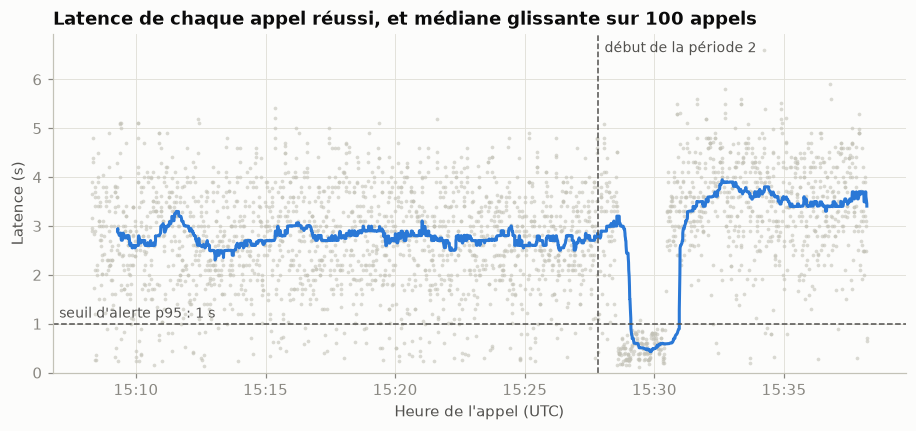

In [8]:
ok = prod[prod["statut_http"] == 200].set_index("date_appel")
fig, ax = plt.subplots()
ax.scatter(ok.index, ok["latence_ms"] / 1000, s=6, color="#c3c2b7", alpha=0.6, linewidths=0)
ax.plot(ok["latence_ms"].rolling(100).median() / 1000, color=COULEURS["Référence"])
ligne_de_seuil(ax, SEUILS["latence_p95_ms"] / 1000, "seuil d'alerte p95 : 1 s", vertical=False)
ligne_de_seuil(ax, COUPURE, "début de la période 2")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylim(0)
ax.set_xlabel("Heure de l'appel (UTC)")
ax.set_ylabel("Latence (s)")
ax.set_title("Latence de chaque appel réussi, et médiane glissante sur 100 appels")
plt.show()

**Lecture.**

- **La latence est bien au-dessus du seuil d'une seconde.** La médiane est d'environ **2,8 s** en période 1 et **3,3 s** en période 2, avec un p95 de 4,3 à 4,8 s.
- **Le modèle représente 95 % de la latence.** La validation des données et le reste du code sont négligeables : le goulot d'étranglement est le calcul du modèle.
- **L'origine : un processeur partagé.** Pendant la simulation, le script envoyait **8 requêtes en même temps** à une API hébergée sur l'offre gratuite de Render, qui ne dispose que de **0,1 CPU**, un dixième de cœur de processeur. Les requêtes simultanées se partagent ce processeur et attendent leur tour.
- **Le creux de 15:28 à 15:30 le confirme.**
  - Au début de la période 2, plusieurs requêtes sont restées bloquées côté client : la réponse s'est perdue sur le réseau, et le script a attendu 120 s avant d'abandonner. Moins de requêtes arrivaient donc en même temps sur l'API.
  - La latence médiane est alors tombée à **0,56 s**, alors que le débit est resté presque le même : 1,4 appel par seconde, contre 1,7 en période 1.
  - **Le débit plafonne donc à environ 1,7 appel par seconde, quelle que soit la charge. Envoyer plus de requêtes en parallèle ne fait qu'allonger la file d'attente.**
- **La latence plus élevée de la période 2** (environ 3,6 s après le creux) n'a pas de cause identifiée à ce stade. A priori, les clients de la période 2 ne demandent pas plus de calcul au modèle. L'hypothèse la plus probable est la variabilité de la machine partagée de l'offre gratuite, à vérifier à l'étape 4.
- **Conclusion** : l'alerte de latence est réelle, mais elle vient de l'infrastructure (le processeur) sous charge, pas d'un défaut du code. C'est le point de départ de l'étape 4, l'optimisation.

## 3. Suivi des prédictions

En production, **on ne sait pas encore si les clients rembourseront** : on ne le saura que des mois plus tard. On ne peut donc pas mesurer directement la performance du modèle. On surveille à la place **ce qu'il produit** : si la distribution des scores ou le taux de refus change nettement par rapport à la référence, c'est un signal d'alerte précoce.

In [9]:
scores = {"Référence": score_ref}
scores.update({p: reussis.loc[reussis["periode"] == p, "probabilite_defaut"] for p in PERIODES})

suivi_scores = pd.DataFrame({
    nom: {
        "Clients scorés": len(s),
        "Score moyen": s.mean(),
        "Score médian": s.median(),
        "Taux de refus (%)": 100 * (s >= THRESHOLD).mean(),
    }
    for nom, s in scores.items()
})
suivi_scores.round(3)

,Référence,Période 1,Période 2
Clients scorés,61502.000,1955.000,983.000
Score moyen,0.387,0.378,0.482
Score médian,0.350,0.342,0.481
Taux de refus (%),30.279,29.258,47.202


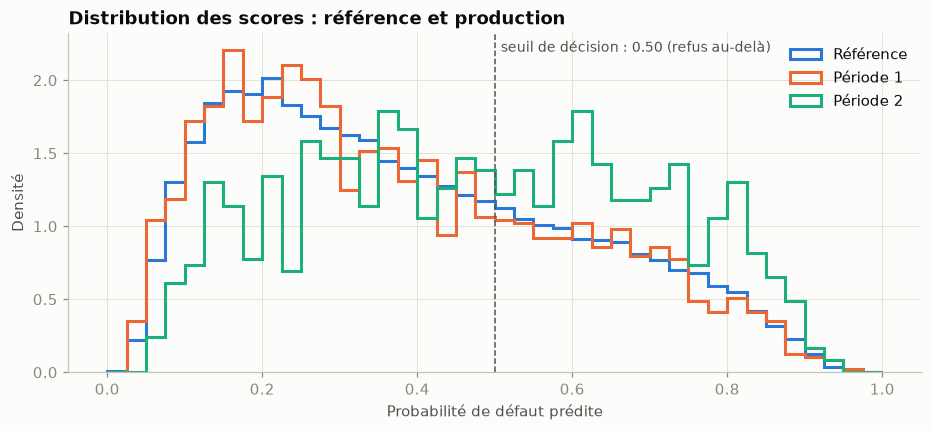

In [10]:
fig, ax = plt.subplots()
bins = np.linspace(0, 1, 41)
for nom, s in scores.items():
    ax.hist(s, bins=bins, density=True, histtype="step", linewidth=2, color=COULEURS[nom], label=nom)
ligne_de_seuil(ax, THRESHOLD, f"seuil de décision : {THRESHOLD:.2f} (refus au-delà)")
ax.set_xlabel("Probabilité de défaut prédite")
ax.set_ylabel("Densité")
ax.set_title("Distribution des scores : référence et production")
ax.legend(loc="upper right")
plt.show()

**La dérive des scores est mesurée avec Evidently**, avec la même méthode que pour les variables d'entrée (voir partie 4) : la distance de Wasserstein normalisée. Une dérive est signalée à partir de 0,1.

In [11]:
DEFINITION_SCORE = DataDefinition(numerical_columns=["probabilite_defaut"])
reference_score = Dataset.from_pandas(score_ref.to_frame(), data_definition=DEFINITION_SCORE)


def derive_du_score(s):
    """Distance de Wasserstein normalisée entre les scores de production et ceux de la référence."""
    rapport = Report([ValueDrift(column="probabilite_defaut")]).run(
        Dataset.from_pandas(s.to_frame(), data_definition=DEFINITION_SCORE), reference_score
    )
    return rapport.dict()["metrics"][0]["value"]


derive_scores = {p: derive_du_score(scores[p]) for p in PERIODES}
pd.Series(derive_scores, name="Dérive des scores (seuil 0,1)").round(3).to_frame()

,"Dérive des scores (seuil 0,1)"
Période 1,0.040
Période 2,0.436


**Lecture.**

- **Période 1 : les scores ont la même distribution que la référence.** La dérive vaut 0,04, sous le seuil de 0,1, et le taux de refus est de 29,3 %, contre 30,3 % sur la référence. Les nouveaux clients sont jugés comme ceux sur lesquels le modèle a été validé.
- **Période 2 : la distribution se décale nettement vers les scores élevés.** La dérive vaut 0,44, plus de quatre fois le seuil. Le score moyen passe de 0,39 à 0,48, et **le taux de refus monte à 47,2 %, soit 17 points de plus**. Le modèle juge les clients jeunes qui empruntent plus comme beaucoup plus risqués.
- **Ce n'est pas forcément une erreur du modèle**, car ces clients sont peut-être réellement plus risqués. Mais c'est exactement le signal qui doit déclencher une analyse :
  - soit la clientèle a changé, à cause de la campagne marketing ;
  - soit le modèle se trompe sur une population qu'il a peu vue.

  On ne pourra trancher qu'en observant les remboursements réels de ces clients.

## 4. Data drift des variables d'entrée

### Comment Evidently détecte une dérive

Pour **chaque variable**, Evidently compare sa distribution en production à sa distribution dans la référence. Il choisit automatiquement la méthode selon la variable :

- **Variables numériques continues** (âge, montants, ratios…) : la **distance de Wasserstein normalisée**. Elle mesure de combien il faut « déplacer » la distribution de production pour retrouver celle de référence, exprimé en **écarts-types de la référence**. Une valeur de 0,1 correspond à un décalage d'environ un dixième d'écart-type.
- **Variables à peu de valeurs** (5 valeurs différentes ou moins, par exemple les indicateurs 0/1) : la **distance de Jensen-Shannon**, qui compare les proportions de chaque valeur. Elle vaut 0 si les proportions sont identiques, et 1 si elles sont totalement différentes.

Dans les deux cas, **une variable est déclarée en dérive quand le score atteint 0,1** (seuil par défaut d'Evidently).

Ces distances sont préférées aux tests statistiques classiques (p-value), parce qu'avec 61 502 clients de référence, un test classique signalerait comme « significative » la moindre petite différence sans importance pratique.

### Quelles variables regarder en priorité ?

Le modèle utilise 215 variables, mais elles ne comptent pas toutes autant. On utilise l'**importance** calculée par LightGBM : le nombre de fois où le modèle utilise la variable pour découper les clients. Une dérive sur une variable très importante est plus grave qu'une dérive sur une variable que le modèle n'utilise presque pas.

In [12]:
importance = pd.Series(model.named_steps["clf"].feature_importances_, index=FEATURES).sort_values(ascending=False)
VARIABLES_IMPORTANTES = list(importance.index[:NB_VARIABLES_IMPORTANTES])
importance.head(NB_VARIABLES_IMPORTANTES).rename("importance (nombre d'utilisations)").to_frame()

,importance (nombre d'utilisations)
PAYMENT_RATE,137
EXT_SOURCE_1,103
EXT_SOURCE_2,103
EXT_SOURCE_3,98
DAYS_BIRTH,60
APPROVED_CNT_PAYMENT_MEAN,50
AMT_ANNUITY,48
INSTAL_DPD_MEAN,41
DAYS_ID_PUBLISH,40
AMT_CREDIT,39


### 4.1 Analyse Evidently, période par période

Evidently produit aussi un **rapport HTML interactif** par période, enregistré dans `reports/`. On l'ouvre dans un navigateur pour explorer chaque variable en détail. Il n'est pas versionné (18 Mo), puisqu'il suffit de relancer le notebook pour le régénérer.

In [13]:
DEFINITION = DataDefinition(numerical_columns=FEATURES)  # les 215 variables sont numériques (one-hot compris)
# 6 clients de la référence ont une valeur infinie sur 2 variables (division par zéro lors de la préparation
# des données) : elles deviennent manquantes, sinon la dérive de ces variables ne peut pas être calculée
reference = Dataset.from_pandas(X_ref.replace([np.inf, -np.inf], np.nan), data_definition=DEFINITION)
(ROOT / "reports").mkdir(exist_ok=True)


def analyser_derive(X_courant, nom_fichier):
    """Compare chaque variable à la référence. Enregistre le rapport HTML et renvoie un tableau par variable."""
    rapport = Report([DataDriftPreset()]).run(Dataset.from_pandas(X_courant, data_definition=DEFINITION), reference)
    rapport.save_html(str(ROOT / "reports" / nom_fichier))
    resultats = [m["config"] | {"score": m["value"]} for m in rapport.dict()["metrics"]
                 if m["config"]["type"].endswith("ValueDrift")]
    tableau = pd.DataFrame(resultats).set_index("column")[["method", "threshold", "score"]]
    tableau["en_derive"] = tableau["score"] >= tableau["threshold"]  # même règle qu'Evidently
    return tableau


derive = {
    p: analyser_derive(X_prod.loc[reussis["periode"] == p], f"drift_periode_{i}.html")
    for i, p in enumerate(PERIODES, start=1)
}

synthese_derive = pd.DataFrame({
    p: {
        "Variables en dérive (sur 215)": t["en_derive"].sum(),
        "Part des variables en dérive (%)": 100 * t["en_derive"].mean(),
        f"Variables en dérive parmi les {NB_VARIABLES_IMPORTANTES} plus importantes": t.loc[VARIABLES_IMPORTANTES, "en_derive"].sum(),
        f"Part des {NB_VARIABLES_IMPORTANTES} plus importantes en dérive (%)": 100 * t.loc[VARIABLES_IMPORTANTES, "en_derive"].mean(),
    }
    for p, t in derive.items()
})
print("Méthodes utilisées :", derive["Période 1"]["method"].value_counts().to_dict())
synthese_derive.round(1)

Méthodes utilisées : {'Wasserstein distance (normed)': 183, 'Jensen-Shannon distance': 32}


,Période 1,Période 2
Variables en dérive (sur 215),27.0,111.0
Part des variables en dérive (%),12.6,51.6
Variables en dérive parmi les 20 plus importantes,7.0,16.0
Part des 20 plus importantes en dérive (%),35.0,80.0


### 4.2 Dérive des variables les plus importantes

Chaque ligne est l'une des 20 variables les plus importantes, de la plus importante (en haut) à la moins importante. Un point à droite du seuil signale une dérive.

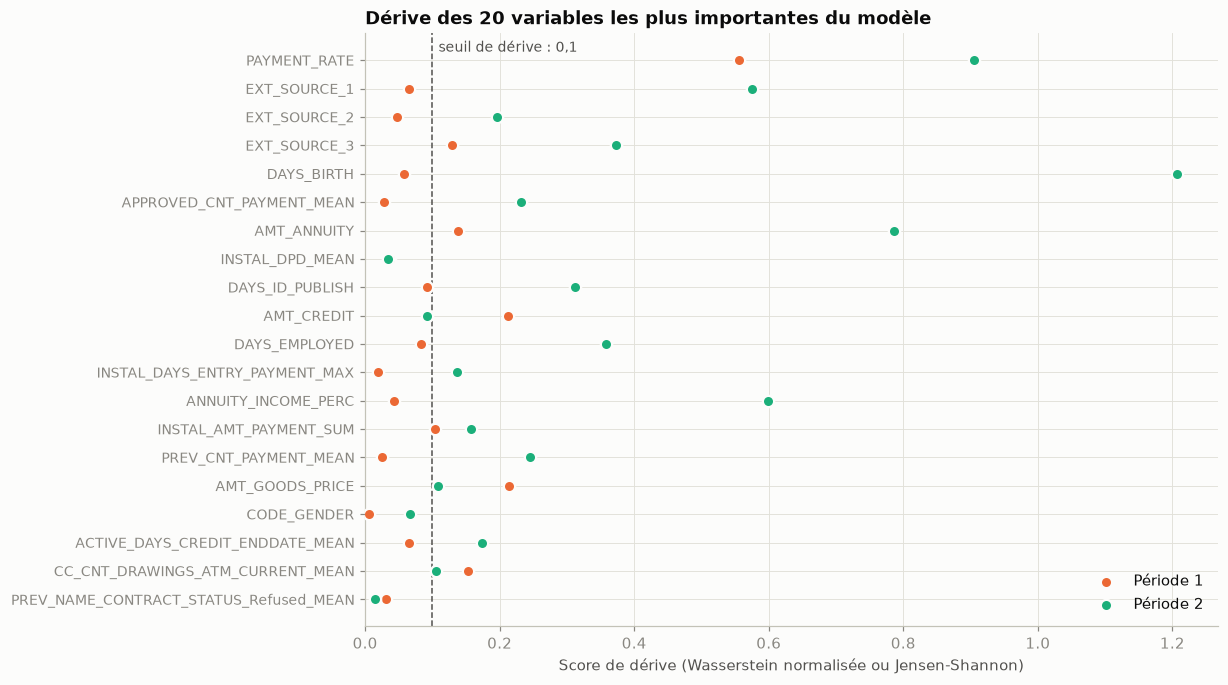

In [14]:
fig, ax = plt.subplots(figsize=(10, 7))
positions = np.arange(NB_VARIABLES_IMPORTANTES)[::-1]  # la plus importante en haut
for p in PERIODES:
    ax.scatter(derive[p].loc[VARIABLES_IMPORTANTES, "score"], positions, s=55, color=COULEURS[p],
               edgecolors="#fcfcfb", linewidths=1.5, label=p, zorder=3)
ligne_de_seuil(ax, 0.1, "seuil de dérive : 0,1")
ax.set_yticks(positions, VARIABLES_IMPORTANTES, fontsize=9)
ax.set_xlim(0)
ax.set_xlabel("Score de dérive (Wasserstein normalisée ou Jensen-Shannon)")
ax.set_title(f"Dérive des {NB_VARIABLES_IMPORTANTES} variables les plus importantes du modèle")
ax.legend(loc="lower right")
plt.show()

### 4.3 Les variables qui dérivent le plus

In [15]:
top_derives = pd.concat(
    {p: t.sort_values("score", ascending=False).head(10).reset_index()[["column", "score"]] for p, t in derive.items()},
    axis=1,
)
top_derives.index = range(1, 11)
top_derives.round(3)

Période 1                         Période 2       
                              column  score                     column  score
1                       PAYMENT_RATE  0.555                 DAYS_BIRTH  1.207
2          AMT_REQ_CREDIT_BUREAU_QRT  0.455               PAYMENT_RATE  0.905
3                 INCOME_CREDIT_PERC  0.312                AMT_ANNUITY  0.786
4                    AMT_GOODS_PRICE  0.214  AMT_REQ_CREDIT_BUREAU_QRT  0.629
5                         AMT_CREDIT  0.212        ANNUITY_INCOME_PERC  0.599
6             DAYS_LAST_PHONE_CHANGE  0.167               EXT_SOURCE_1  0.575
7   CC_CNT_DRAWINGS_ATM_CURRENT_MEAN  0.153     CLOSED_DAYS_CREDIT_MIN  0.443
8      NAME_CONTRACT_TYPE_Cash_loans  0.150    CLOSED_DAYS_CREDIT_MEAN  0.429
9                   AMT_INCOME_TOTAL  0.149               EXT_SOURCE_3  0.372
10    CLOSED_DAYS_CREDIT_UPDATE_MEAN  0.148              DAYS_EMPLOYED  0.358

### 4.4 Quatre variables clés, en détail

On compare directement les distributions de référence et de production pour quatre variables :
- l'**âge** et le **montant du crédit**, visés par le scénario de la période 2 ;
- `PAYMENT_RATE` (annuité / montant du crédit), la variable la plus importante du modèle ;
- `EXT_SOURCE_1`, un score externe très important pour le modèle.

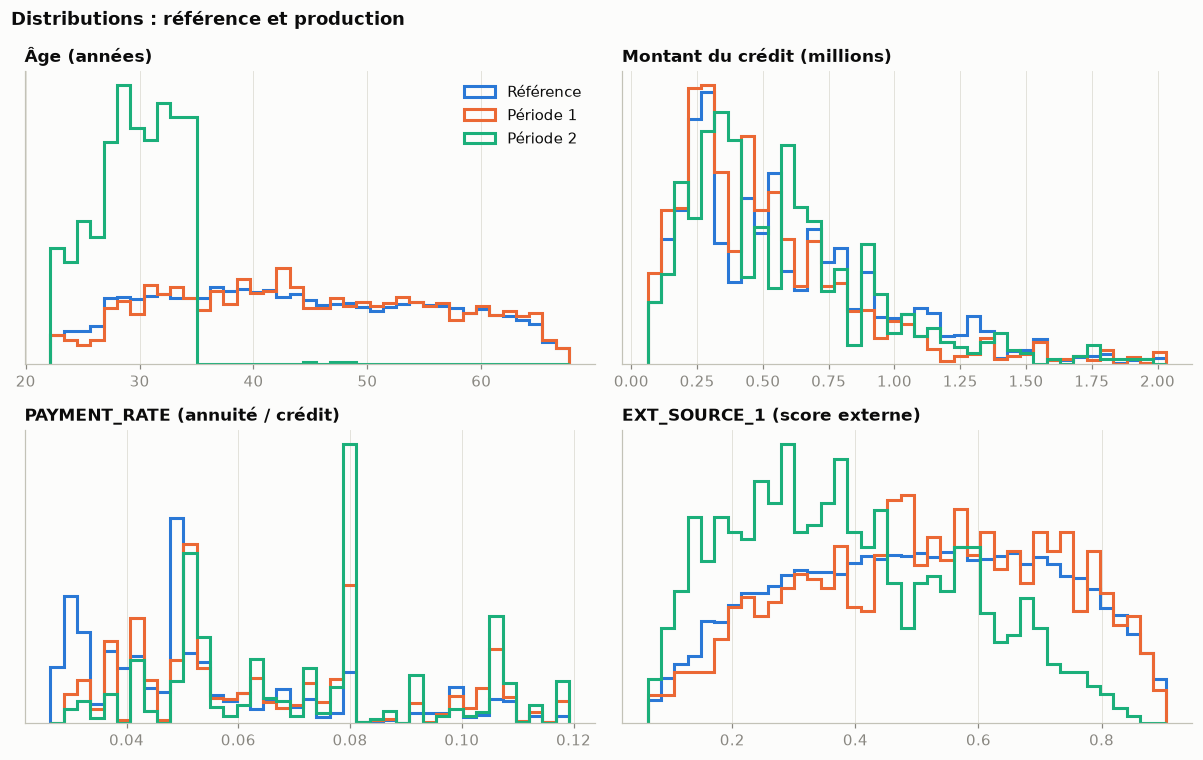

In [16]:
VARIABLES_CLES = {
    "DAYS_BIRTH": ("Âge (années)", lambda s: -s / 365),
    "AMT_CREDIT": ("Montant du crédit (millions)", lambda s: s / 1e6),
    "PAYMENT_RATE": ("PAYMENT_RATE (annuité / crédit)", lambda s: s),
    "EXT_SOURCE_1": ("EXT_SOURCE_1 (score externe)", lambda s: s),
}
jeux = {"Référence": X_ref} | {p: X_prod.loc[reussis["periode"] == p] for p in PERIODES}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (variable, (titre, transformer)) in zip(axes.flat, VARIABLES_CLES.items()):
    # Bornes communes, coupées aux 0,5 % extrêmes de la référence pour la lisibilité
    ref = transformer(X_ref[variable]).dropna()
    bins = np.linspace(ref.quantile(0.005), ref.quantile(0.995), 40)
    for nom, X in jeux.items():
        ax.hist(transformer(X[variable]).dropna(), bins=bins, density=True, histtype="step", linewidth=2,
                color=COULEURS[nom], label=nom)
    ax.set_title(titre, fontsize=11)
    ax.set_yticks([])
axes.flat[0].legend(loc="upper right")
fig.suptitle("Distributions : référence et production", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Lecture.**

**Période 1 : une dérive « naturelle », sans conséquence sur les scores.**
- 27 variables sur 215 dérivent (13 %), dont 7 des 20 plus importantes (35 %). C'est sous le seuil d'alerte de 50 %.
- La plus touchée est `PAYMENT_RATE` (annuité / crédit), **la variable la plus importante du modèle**, avec un score de 0,56. Viennent ensuite les montants : `INCOME_CREDIT_PERC`, `AMT_GOODS_PRICE`, `AMT_CREDIT`.
- **Ce n'est pas un défaut de notre chaîne : cette différence existe dans les données Kaggle d'origine.**
  - Le jeu de test ne contient presque pas de crédits renouvelables (0,9 %, contre 9,5 % à l'entraînement), qui ont un rapport annuité / crédit particulier.
  - Ses montants de crédit sont plus faibles : médiane de 450 000, contre 513 500.
- **Malgré cette dérive sur la variable la plus importante, les scores n'ont pas bougé** (partie 3). C'est pourquoi on ne déclenche pas d'alerte sur une seule variable : il faut regarder l'ensemble, et surtout l'effet sur les prédictions. La situation est à surveiller, sans action immédiate.

**Période 2 : une dérive forte, bien détectée.**
- 111 variables sur 215 dérivent (52 %), dont **16 des 20 plus importantes (80 %)**.
- **L'âge (`DAYS_BIRTH`) est la variable qui dérive le plus**, avec un score de 1,21. C'est attendu : tous les clients ont moins de 35 ans. Les montants modifiés suivent (`AMT_ANNUITY`, `ANNUITY_INCOME_PERC`).
- **Des variables que la simulation n'a pas modifiées dérivent aussi**, parce qu'elles sont liées à l'âge :
  - un historique de crédit plus court (`CLOSED_DAYS_CREDIT_*`) ;
  - une ancienneté dans l'emploi plus faible (`DAYS_EMPLOYED`) ;
  - des scores externes plus bas (`EXT_SOURCE_1`, `EXT_SOURCE_3`).

  Une dérive réelle touche rarement une seule variable.
- **Un détail intéressant : `AMT_CREDIT` dérive moins en période 2 qu'en période 1.** La hausse de 30 % des montants compense le fait que les clients du jeu de test empruntent moins que ceux de la référence. Une dérive peut donc en masquer une autre : il faut toujours comparer à la référence, pas seulement à la période précédente.

**Pour explorer chaque variable**, ouvrez les rapports Evidently `reports/drift_periode_1.html` et `reports/drift_periode_2.html` dans un navigateur.

## 5. Alertes automatiques

On applique les règles définies au début du notebook. Chaque règle donne **✅ OK** ou **🚨 ALERTE** pour chaque période. C'est ce tableau qu'on consulte en premier quand on relance le notebook.

In [17]:
refus_ref = suivi_scores.loc["Taux de refus (%)", "Référence"]


def appliquer_regles(p):
    """Applique les règles d'alerte à une période : {règle (seuil): (valeur mesurée, alerte ?)}."""
    o = operationnel[p]
    taux_erreur = o["Taux d'erreur (%)"]
    erreurs_500 = o["Erreurs 500 (erreur interne)"]
    latence_p95 = o["Latence p95 (ms)"]
    part_importantes = 100 * derive[p].loc[VARIABLES_IMPORTANTES, "en_derive"].mean()
    ecart_refus = suivi_scores.loc["Taux de refus (%)", p] - refus_ref
    return {
        f"Taux d'erreur (> {SEUILS['taux_erreur_pct']} %)":
            (f"{taux_erreur:.1f} %", taux_erreur > SEUILS["taux_erreur_pct"]),
        f"Erreurs internes 500 (> {SEUILS['erreurs_500']})":
            (f"{erreurs_500:.0f}", erreurs_500 > SEUILS["erreurs_500"]),
        f"Latence p95 (> {SEUILS['latence_p95_ms']} ms)":
            (f"{latence_p95:.0f} ms", latence_p95 > SEUILS["latence_p95_ms"]),
        f"Variables importantes en dérive (>= {SEUILS['part_variables_importantes_pct']} % des {NB_VARIABLES_IMPORTANTES})":
            (f"{part_importantes:.0f} %", part_importantes >= SEUILS["part_variables_importantes_pct"]),
        f"Dérive des scores (>= {SEUILS['derive_score']})":
            (f"{derive_scores[p]:.3f}", derive_scores[p] >= SEUILS["derive_score"]),
        f"Écart du taux de refus / référence (> {SEUILS['ecart_refus_points']} points)":
            (f"{ecart_refus:+.1f} points", abs(ecart_refus) > SEUILS["ecart_refus_points"]),
    }


alertes = pd.DataFrame({
    p: {regle: f"{valeur}  {'🚨 ALERTE' if alerte else '✅ OK'}" for regle, (valeur, alerte) in appliquer_regles(p).items()}
    for p in PERIODES
})
alertes.index.name = "Règle (seuil)"
alertes

,Période 1,Période 2
Règle (seuil),,
Taux d'erreur (> 5 %),2.1 % ✅ OK,2.0 % ✅ OK
Erreurs internes 500 (> 0),0 ✅ OK,0 ✅ OK
Latence p95 (> 1000 ms),4304 ms 🚨 ALERTE,4797 ms 🚨 ALERTE
Variables importantes en dérive (>= 50 % des 20),35 % ✅ OK,80 % 🚨 ALERTE
Dérive des scores (>= 0.1),0.040 ✅ OK,0.436 🚨 ALERTE
Écart du taux de refus / référence (> 10 points),-1.0 points ✅ OK,+16.9 points 🚨 ALERTE


**Lecture.**

- **Période 1 : une seule alerte, la latence.** Elle vient de l'infrastructure sous charge (partie 2). Il n'y a pas de problème de données ni de prédictions.
- **Période 2 : en plus de la latence, trois alertes de dérive se déclenchent ensemble** : variables importantes, scores et taux de refus. La campagne simulée est détectée sous trois angles à la fois, ce qui rend l'alerte fiable.
- **Aucune alerte sur les erreurs** : les applications clientes envoient très peu de données invalides, et l'API n'a jamais planté.

## 6. Conclusions et points de vigilance

### Ce que montre l'analyse

| Constat | Gravité | Action proposée |
|---|---|---|
| Latence p95 de 4 à 5 s sous charge, pour un seuil de 1 s. Le modèle représente 95 % du temps, et le débit plafonne à environ 1,7 appel par seconde. | Élevée | Étape 4 : profilage, optimisation de l'inférence (ONNX Runtime), écriture en base en tâche de fond, matériel plus puissant que l'offre gratuite (0,1 CPU) |
| Période 2 : dérive forte des entrées (80 % des variables importantes) et des scores (taux de refus +17 points) | Élevée | Prévenir le métier (Crédit Express) et vérifier si la clientèle a changé. Suivre les remboursements de ces clients, puis envisager un réentraînement incluant des clients jeunes dès que leurs résultats sont connus. |
| Période 1 : dérive naturelle de `PAYMENT_RATE` et des montants (différence entre les jeux Kaggle), sans effet sur les scores | Faible | Surveiller, sans action |
| 8 réponses jamais reçues par le client, alors que la base les enregistre comme réussies | Moyenne | Ajouter une sonde externe qui appelle l'API régulièrement (« monitoring synthétique ») : le monitoring côté serveur ne voit pas ces pannes |
| L'API accepte une valeur infinie (`Infinity`), mais PostgreSQL ne peut pas la stocker en JSON : l'appel serait servi sans être enregistré | Moyenne | Refuser les valeurs infinies dans la validation de l'API (erreur 422) |
| 2 vrais clients refusés à cause d'une annuité manquante | Faible | Décider avec le métier : champ facultatif, ou traitement manuel |

### Points de vigilance pour le suivi en production

- **Il n'y a pas de vérité terrain immédiate.** On ne sait si un client rembourse que des mois plus tard. La dérive des entrées et des scores sert d'**alerte précoce**. La performance réelle (AUC, coût métier) ne pourra être recalculée qu'avec ces résultats.
- **Une dérive n'est pas forcément un problème**, comme le montre la période 1. Il faut regarder les variables importantes et l'effet sur les scores, pas seulement le nombre de variables touchées.
- **Le volume compte.** Les mesures de dérive ont besoin d'assez de données : en dessous de quelques centaines d'appels par période, elles sont peu fiables.
- **La référence doit évoluer avec le modèle.** Le jeu de validation représente la clientèle au moment de l'entraînement. Si le modèle est réentraîné, la référence doit être mise à jour avec lui.
- **Cette étude a des limites** : le trafic est simulé (clients du jeu de test Kaggle), et la période 2 est une dérive construite artificiellement.
- **RGPD** : les données stockées ne contiennent aucun identifiant client, mais restent des données personnelles. Il faudra fixer une durée de conservation avec le métier, par exemple une purge des appels de plus de 6 mois.

### Comment relancer l'analyse

1. Installez les dépendances : `pip install -r requirements-analyse.txt`.
2. Vérifiez que le fichier `.env` contient `DATABASE_URL`, et que `data/prepared_dataset.parquet` est présent.
3. Exécutez toutes les cellules, dans VS Code ou Jupyter, ou en ligne de commande : `jupyter nbconvert --to notebook --execute --inplace notebooks/02_analyse_drift_monitoring.ipynb`.
4. Lisez d'abord le **tableau d'alertes** (partie 5), puis le détail des parties concernées.

En production réelle, cette analyse serait lancée automatiquement chaque semaine, par exemple par une tâche planifiée GitHub Actions, et les alertes seraient envoyées à l'équipe.